# Automatic differentiation with PyTorch

`DarkEmulator2(autodiff="torch")` returns `P(k)` and `C_ell` as differentiable PyTorch tensors.

- exact derivatives, no finite-difference step
- derivatives for all parameters in one call, also on GPUs
- usable in Fisher matrices, optimizers and HMC/NUTS ([Pyro](https://docs.pyro.ai/))

## Setup

From a source checkout, run the commented install command below with `notebook/` as the working directory. It installs this checkout and the notebook dependencies (`matplotlib` and `pyro-ppl`).

In [1]:
# %pip install .. matplotlib pyro-ppl

In [2]:
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import pyro
import pyro.distributions as dist
from pyro.infer import MCMC, NUTS
from dark_emulator2 import DarkEmulator2

device = "cuda" if torch.cuda.is_available() else "cpu"
de = DarkEmulator2()
emu = DarkEmulator2(autodiff="torch", device=device, dtype=torch.float64)

fiducial = {
    "Omega_m": 0.3156,
    "h0": 0.6723,
    "omega_b": 0.02225,
    "sigma8": 0.831,
    "ns": 0.9645,
    "Mnu": 0.06,
    "Omega_k": 0.0,
    "w0": -1.0,
    "wa": 0.0,
}

## Parameter inputs

The input dictionary contains nine independent parameters: `Omega_m`, `omega_b`, `ns`, `Mnu`, `Omega_k`, `w0`, `wa`, `h0` and an amplitude. The examples use `sigma8`; `As` or `ln(10^10As)` can be used instead and remain differentiable. Remove the other amplitude entries first, since a non-None `sigma8` takes precedence over `ln(10^10As)` and `As`.

Pass PyTorch tensors directly in a dictionary, as in `ln_cl()` and `model()` below. Use `emu.param.set_param()` only to prepare ordinary numerical values beforehand: calling it inside a gradient function can disconnect the inputs from the result. The differentiable calls use the independent parameters above, so extra `omega_cdm` and `Omega_de` entries from a completed dictionary do not need updating.

With autodiff enabled, `get_sigma8()` and `get_lnAs()` return values without updating the input dictionary. Assign their return values explicitly when needed.

## Device and precision

- `device`: `"cpu"` (default), `"cuda"`, `"cuda:N"`
- `dtype`: `torch.get_default_dtype()` by default; float64 is recommended for HMC ([torch.set_default_dtype](https://docs.pytorch.org/docs/stable/generated/torch.set_default_dtype.html))
- `get_pk`, `get_lin_pk`, `get_cl_limber`, `get_lin_cl_limber`, `get_sigma8` and `get_lnAs` return tensors; other methods return numpy arrays

In [3]:
k, pk = emu.get_pk(fiducial)
print(pk.device, pk.dtype, tuple(pk.shape))

cuda:0 torch.float64 (301,)


## Same outputs as `DarkEmulator2`

In [4]:
zred = [0.0, 0.5, 1.0]
k, pk = emu.get_pk(fiducial, zred=zred, pk_type="total")
_, pk_ref = de.get_pk(fiducial, zred=zred, pk_type="total")
print("P(k)  max relative difference:", np.max(np.abs(pk.cpu().numpy() / pk_ref - 1)))

ell_ref, cl = emu.get_cl_limber(fiducial)
_, cl_ref = de.get_cl_limber(fiducial)
print("C_ell max relative difference:", np.max(np.abs(cl.cpu().numpy() / cl_ref - 1)))

P(k)  max relative difference: 1.2742985526781325e-06


C_ell max relative difference: 7.769473111540748e-07


## Exact derivatives

Finite differences of `DarkEmulator2` depend on the step; automatic differentiation does not.

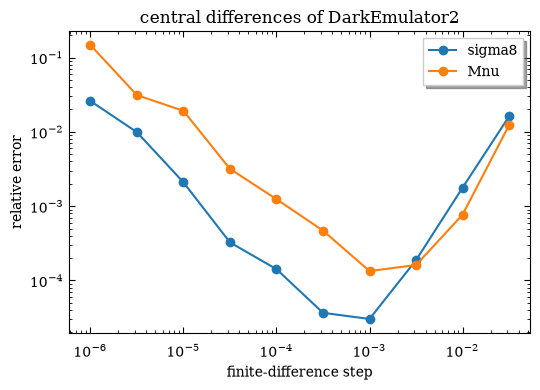

In [5]:
z_cl = np.linspace(0.0, 1.0, 61)
k_cl = np.logspace(-3, 2, 301)
ell = np.logspace(1, 4, 30)
names = ["Omega_m", "sigma8", "h0", "ns", "omega_b", "Mnu", "w0", "wa", "Omega_k"]


def ln_cl(theta):
    return torch.log(emu.get_cl_limber({**fiducial, **dict(zip(names, theta))}, zlist=z_cl, klist=k_cl, llist=ell)[1])


theta0 = torch.tensor([fiducial[n] for n in names], dtype=torch.float64, device=device)
jac = torch.func.jacfwd(ln_cl)(theta0).cpu().numpy()


def ln_cl_de2(p):
    return np.log(de.get_cl_limber(p, zlist=z_cl, klist=k_cl, llist=ell)[1])


steps = np.logspace(-1.5, -6, 10)
fig, ax = plt.subplots(figsize=(5.5, 4))
for name in ["sigma8", "Mnu"]:
    i = names.index(name)
    errors = []
    for h in steps:
        fd = (ln_cl_de2({**fiducial, name: fiducial[name] + h}) - ln_cl_de2({**fiducial, name: fiducial[name] - h})) / (2 * h)
        errors.append(np.max(np.abs(fd - jac[:, i])) / np.max(np.abs(jac[:, i])))
    ax.loglog(steps, errors, "o-", label=name)
ax.set_xlabel("finite-difference step")
ax.set_ylabel("relative error")
ax.set_title("central differences of DarkEmulator2")
ax.legend()
plt.tight_layout()
plt.show()

## Fast gradients

Derivatives for 9 parameters: one call vs. 18 evaluations with central differences.

In [6]:
t0 = time.perf_counter()
torch.func.jacfwd(ln_cl)(theta0).cpu()
t_ad = time.perf_counter() - t0

t0 = time.perf_counter()
ln_cl_de2(fiducial)
t_de2 = time.perf_counter() - t0

print(f"derivatives of C_ell with respect to {len(names)} parameters:")
print(f"  automatic differentiation:              {t_ad:.3g} s")
print(f"  central differences with DarkEmulator2: {2 * len(names) * t_de2:.3g} s ({2 * len(names)} evaluations)")

derivatives of C_ell with respect to 9 parameters:
  automatic differentiation:              0.0439 s
  central differences with DarkEmulator2: 2.68 s (18 evaluations)


## Fisher matrix and NUTS

- Toy likelihood (not a survey analysis): fake total-matter `P(k,z)` at four redshifts, with 5% error on `ln P`.
- Infer `Omega_m`, `sigma8`, `h0` and `ns` together; other parameters stay at their fiducial values. The fake data use `Omega_m = 0.45`, `sigma8 = 0.62`.
- Two chains retain 5000 samples each after 1000 warmup steps. A full mass matrix adapts to parameter correlations.
- Runtime reference: on an NVIDIA A100 with float64, this NUTS cell took about 72 minutes with these settings. Reduce `n_samples` for a shorter trial run.
- The prior box corners are checked against the DE2 support. The local likelihood Fisher errors ignore the finite priors.
- The corner plots show KDE-smoothed NUTS marginals and 15% / 38% / 68% / 95% posterior regions, with the fake data truth in red. The left view zooms in on the posterior; the right view shows the full prior ranges.
- To try all nine parameters, set `sampled_names = list(prior_bounds)`; sampling and plotting use the selected names automatically. This takes longer and weakly constrained parameters can depend on their priors.


In [7]:
from itertools import product

z_data = np.array([0.0, 0.5, 1.0, 2.0])
k_data = np.logspace(-2, np.log10(5.0), 32)
sigma_logpk = 0.05

sampled_names = ["Omega_m", "sigma8", "h0", "ns"]
prior_bounds = {
    "Omega_m": (0.40, 0.50), "sigma8": (0.56, 0.68),
    "h0": (0.64, 0.71), "ns": (0.94, 0.99),
    "omega_b": (0.021, 0.0235), "Mnu": (0.0, 0.30),
    "w0": (-1.2, -0.8), "wa": (-0.3, 0.3), "Omega_k": (-0.03, 0.03),
}
# To sample all nine parameters, use: sampled_names = list(prior_bounds)
truth_param = {**fiducial, "Omega_m": 0.45, "sigma8": 0.62}
truth = np.array([truth_param[name] for name in sampled_names])
corners = product(*(prior_bounds[name] for name in sampled_names))
assert all(de.is_in_support({**truth_param, **dict(zip(sampled_names, point))}) for point in corners)
print("sampled parameters:", sampled_names)
print("all prior box corners are in support")


def model_ln_pk(theta):
    param = {**truth_param, **dict(zip(sampled_names, theta))}
    return torch.log(emu.get_pk(param, zred=z_data, klist=k_data, pk_type="total")[1]).reshape(-1)


theta_truth = torch.tensor(truth, dtype=torch.float64, device=device)
log_pk_data = model_ln_pk(theta_truth)
J = torch.func.jacfwd(model_ln_pk)(theta_truth).cpu().numpy()

fisher = J.T @ J / sigma_logpk**2
fisher_condition = np.linalg.cond(fisher)
print(f"likelihood Fisher condition number: {fisher_condition:.3g}")
if fisher_condition < 1e12:
    fisher_cov = np.linalg.inv(fisher)
    print("local Fisher 1-sigma errors:", dict(zip(sampled_names, np.sqrt(np.diag(fisher_cov)))))
else:
    fisher_cov = None
    print("The likelihood Fisher matrix is nearly singular; finite priors constrain weak directions.")


def uniform(lo, hi):
    return dist.Uniform(torch.tensor(lo, dtype=torch.float64, device=device),
                        torch.tensor(hi, dtype=torch.float64, device=device))


def model():
    theta = torch.stack([pyro.sample(name, uniform(*prior_bounds[name])) for name in sampled_names])
    pyro.sample("obs", dist.Normal(model_ln_pk(theta), sigma_logpk).to_event(1), obs=log_pk_data)


sampled parameters: ['Omega_m', 'sigma8', 'h0', 'ns']
all prior box corners are in support
likelihood Fisher condition number: 911
local Fisher 1-sigma errors: {'Omega_m': np.float64(0.011610984472308843), 'sigma8': np.float64(0.0024100348148657874), 'h0': np.float64(0.024522039001031795), 'ns': np.float64(0.021874203679321188)}


In [8]:
from pyro.ops.stats import effective_sample_size, split_gelman_rubin

n_warmup, n_samples, n_chains = 1000, 5000, 2
chains, chain_diagnostics = [], []


def progress(kernel, sample, stage, i):
    if (i + 1) % 1000 == 0:
        print(f"  {stage}: {i + 1} iterations", flush=True)


t0 = time.perf_counter()
for chain in range(n_chains):
    pyro.set_rng_seed(chain)
    kernel = NUTS(model, full_mass=True, target_accept_prob=0.9)
    mcmc = MCMC(kernel, num_samples=n_samples, warmup_steps=n_warmup,
                disable_progbar=True, hook_fn=progress)
    mcmc.run()
    chains.append(mcmc.get_samples())
    chain_diagnostics.append(mcmc.diagnostics())
    print(f"chain {chain + 1}/{n_chains} finished in {time.perf_counter() - t0:.0f} s", flush=True)

samples_by_chain = {name: torch.stack([chain[name] for chain in chains]) for name in sampled_names}
diagnostics = {
    name: {"mean": float(values.mean()), "std": float(values.std()),
           "n_eff": float(effective_sample_size(values)), "r_hat": float(split_gelman_rubin(values))}
    for name, values in samples_by_chain.items()
}
divergences = sum(len(indices) for diag in chain_diagnostics for indices in diag["divergences"].values())
print(f"NUTS: {n_chains} chains, {n_chains * n_samples} retained samples in {time.perf_counter() - t0:.0f} s")
print("parameter       mean         std       n_eff       r_hat")
for name, stat in diagnostics.items():
    print(f"{name:10s} {stat['mean']:11.5f} {stat['std']:11.5f} {stat['n_eff']:11.1f} {stat['r_hat']:11.4f}")
print("divergences:", divergences)
samples = {name: values.detach().cpu().numpy().reshape(-1) for name, values in samples_by_chain.items()}


  Warmup: 1000 iterations


  Sample: 1000 iterations


  Sample: 2000 iterations


  Sample: 3000 iterations


  Sample: 4000 iterations


...

  Sample: 3000 iterations


  Sample: 4000 iterations


  Sample: 5000 iterations


chain 2/2 finished in 4301 s


NUTS: 2 chains, 10000 retained samples in 4301 s
parameter       mean         std       n_eff       r_hat
Omega_m        0.45002     0.01020      2960.4      1.0002
sigma8         0.62001     0.00226      4015.1      1.0000
h0             0.67279     0.01627      2074.1      1.0005
ns             0.96433     0.01296      2550.7      1.0016
divergences: 0


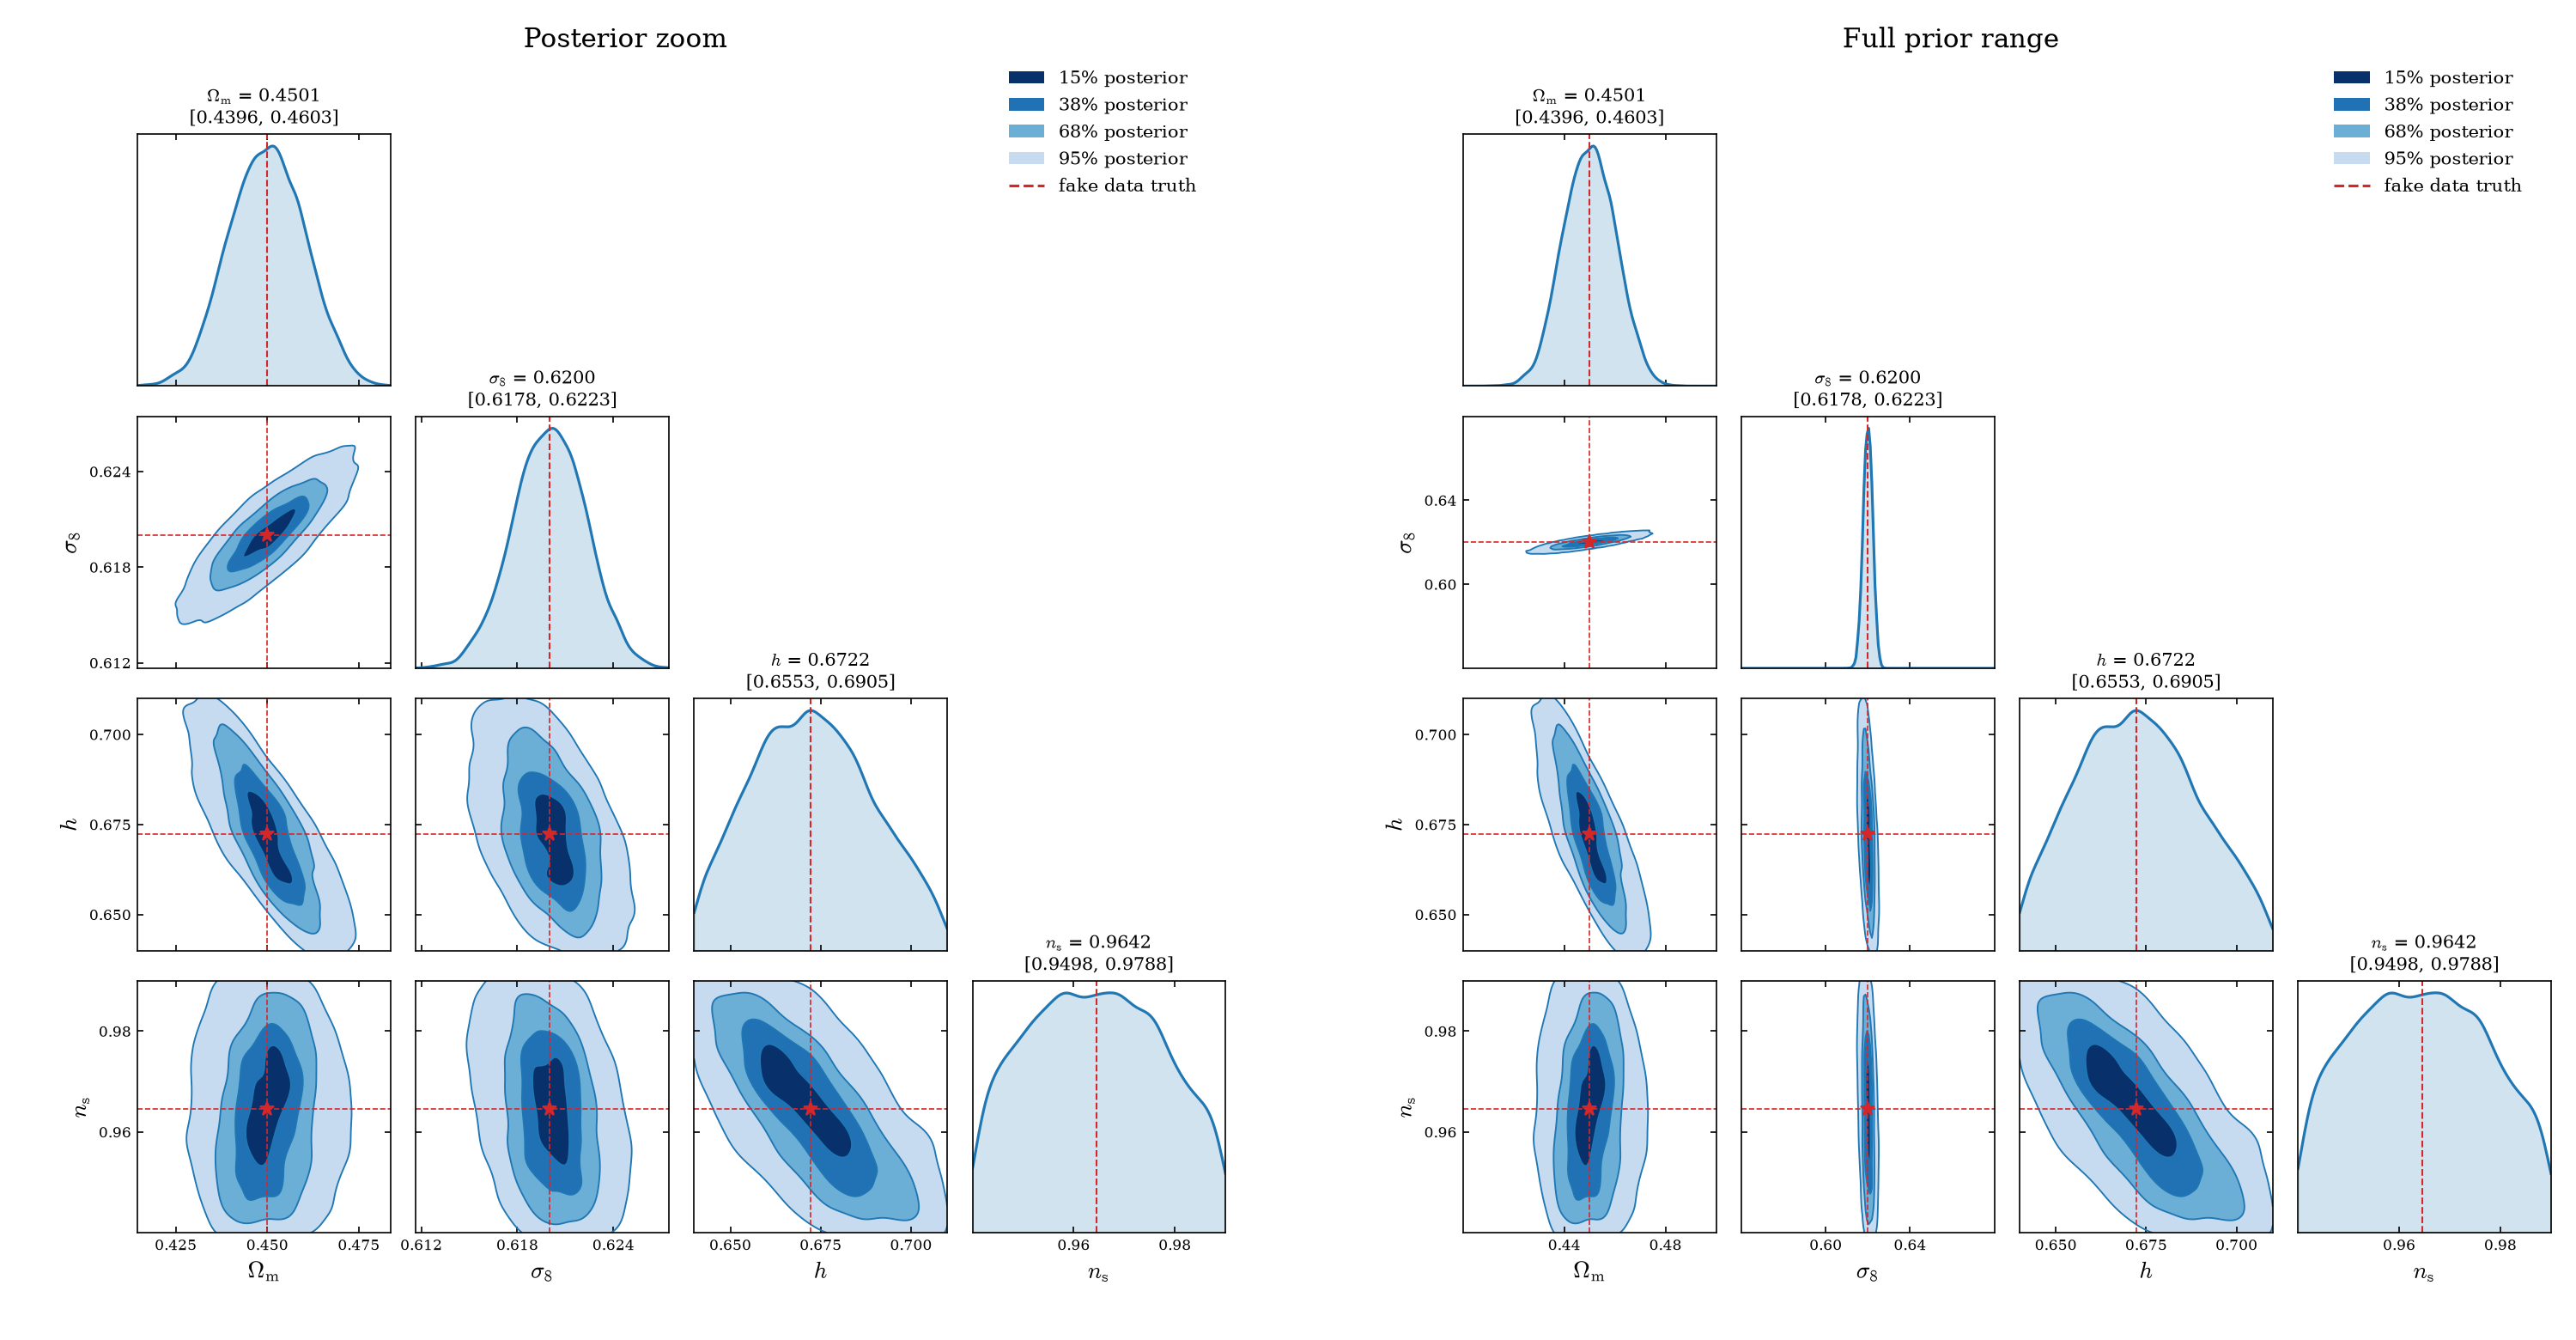

In [9]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator
from scipy.stats import gaussian_kde

labels = {
    "Omega_m": r"$\Omega_{\rm m}$", "sigma8": r"$\sigma_8$", "h0": r"$h$", "ns": r"$n_{\rm s}$",
    "omega_b": r"$\omega_{\rm b}$", "Mnu": r"$M_\nu\,[{\rm eV}]$",
    "w0": r"$w_0$", "wa": r"$w_a$", "Omega_k": r"$\Omega_k$",
}
# Show the posterior at a useful scale while respecting the prior boundaries.
plot_limits = {}
for name in sampled_names:
    lo, hi = np.quantile(samples[name], [0.001, 0.999])
    padding = 0.08 * (hi - lo)
    plot_limits[name] = (max(prior_bounds[name][0], lo - padding),
                         min(prior_bounds[name][1], hi + padding))

ndim = len(sampled_names)
fig = plt.figure(figsize=(5.0 * ndim, 2.6 * ndim))
views = [("Posterior zoom", plot_limits), ("Full prior range", prior_bounds)]
for subfig, (title, limits) in zip(fig.subfigures(1, 2, wspace=0.06), views):
    axes = subfig.subplots(ndim, ndim, squeeze=False)
    subfig.suptitle(title, fontsize=15)
    for row, yname in enumerate(sampled_names):
        for col, xname in enumerate(sampled_names):
            ax = axes[row, col]
            if col > row:
                ax.set_visible(False)
                continue
            x = np.linspace(*limits[xname], 160)
            if row == col:
                density = gaussian_kde(samples[xname])(x)
                ax.fill_between(x, density, color="C0", alpha=0.20)
                ax.plot(x, density, color="C0", lw=1.5)
                ax.axvline(truth_param[xname], color="C3", ls="--", lw=1)
                ax.set_ylim(bottom=0)
                ax.set_yticks([])
                lo, mid, hi = np.quantile(samples[xname], [0.16, 0.50, 0.84])
                ax.set_title(f"{labels[xname]} = {mid:.4f}\n[{lo:.4f}, {hi:.4f}]", fontsize=10)
            else:
                y = np.linspace(*limits[yname], 160)
                xx, yy = np.meshgrid(x, y)
                density = gaussian_kde(np.vstack([samples[xname], samples[yname]]))(
                    np.vstack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
                ordered = np.sort(density.ravel())[::-1]
                mass = np.cumsum(ordered) / ordered.sum()
                levels = [ordered[min(np.searchsorted(mass, prob), len(ordered) - 1)] for prob in [0.95, 0.68, 0.38, 0.15]]
                ax.contourf(xx, yy, density, levels=[*levels, density.max() * 1.001],
                            colors=["#c6dbef", "#6baed6", "#2171b5", "#08306b"])
                ax.contour(xx, yy, density, levels=levels, colors="C0", linewidths=0.9)
                ax.axvline(truth_param[xname], color="C3", ls="--", lw=0.8)
                ax.axhline(truth_param[yname], color="C3", ls="--", lw=0.8)
                ax.plot(truth_param[xname], truth_param[yname], "*", color="C3", ms=8)
                ax.set_ylim(*limits[yname])
            ax.set_xlim(*limits[xname])
            ax.xaxis.set_major_locator(MaxNLocator(nbins=3, prune="both"))
            if row != col:
                ax.yaxis.set_major_locator(MaxNLocator(nbins=3, prune="both"))
            ax.tick_params(direction="in", top=True, right=True, labelsize=8)
            if row == ndim - 1:
                ax.set_xlabel(labels[xname], fontsize=13)
            else:
                ax.tick_params(labelbottom=False)
            if col == 0 and row > 0:
                ax.set_ylabel(labels[yname], fontsize=13)
            elif row != col:
                ax.tick_params(labelleft=False)

    subfig.legend(handles=[Patch(facecolor="#08306b", label="15% posterior"),
                        Patch(facecolor="#2171b5", label="38% posterior"),
                        Patch(facecolor="#6baed6", label="68% posterior"),
                        Patch(facecolor="#c6dbef", label="95% posterior"),
                        Line2D([], [], color="C3", ls="--", label="fake data truth")],
               loc="upper right", bbox_to_anchor=(0.97, 0.96), frameon=False)
    subfig.subplots_adjust(left=0.11, right=0.98, bottom=0.08, top=0.90, hspace=0.12, wspace=0.10)
plt.show()


## Many cosmologies in one call

Parameters can be arrays.

In [10]:
n = 500
rng = np.random.default_rng(0)
batch = {**fiducial, "Omega_m": torch.tensor(rng.uniform(0.25, 0.35, n), device=device), "sigma8": torch.tensor(rng.uniform(0.75, 0.9, n), device=device)}
emu.get_pk(fiducial, zred=0.5)

t0 = time.perf_counter()
k, pk_batch = emu.get_pk(batch, zred=0.5)
pk_batch = pk_batch.cpu()
t_batch = time.perf_counter() - t0

t0 = time.perf_counter()
for om, s8 in zip(batch["Omega_m"][:50].tolist(), batch["sigma8"][:50].tolist()):
    de.get_pk({**fiducial, "Omega_m": om, "sigma8": s8}, zred=0.5)
t_loop = (time.perf_counter() - t0) / 50 * n

print(f"P(k) of {n} cosmologies {tuple(pk_batch.shape)}: one call {t_batch:.3g} s | DarkEmulator2 loop about {t_loop:.3g} s")

P(k) of 500 cosmologies (500, 301): one call 0.0105 s | DarkEmulator2 loop about 3.17 s


## Notes

- Grids (`zred`, `klist`, `zlist`, `llist`, `src_dist`) must be fixed numpy arrays.
- Outputs differ from `DarkEmulator2` at the 1e-6 level (single-precision networks).
- Derivatives of `C_ell` are exact between the switches of the shot-noise cutoff.
- For production analyses, pass `P(k,z)` to the downstream likelihood when possible.